# Exploratory Data Analysis (EDA) - EPB Detection
This notebook analyzes the processed satellite imagery (NASA GOLD) and the validation results (GNSS correlation).

In [1]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import cv2

# specific encoding to avoid errors
sns.set_theme(style="whitegrid")

DATA_DIR = "../data/processed/images_224x224"
RESULTS_FILE = "../results/validation_results.csv"


## 1. Dataset Overview

Total Processed Images: 350


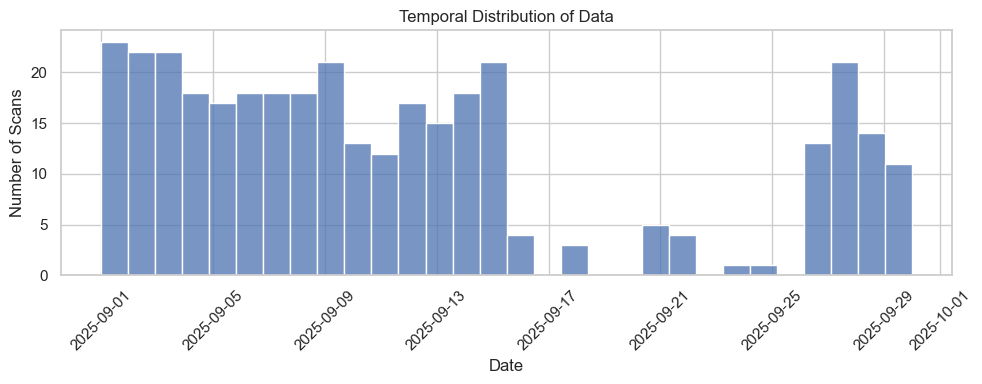

In [2]:
image_files = glob.glob(os.path.join(DATA_DIR, "*.png"))
print(f"Total Processed Images: {len(image_files)}")

def extract_date(filename):
    # Format: gold_l2_nmax_YYYY_DOY_...
    parts = os.path.basename(filename).split('_')
    year = int(parts[3])
    doy = int(parts[4])
    return pd.Timestamp(f"{year}-01-01") + pd.Timedelta(days=doy-1)

dates = [extract_date(f) for f in image_files]
df_meta = pd.DataFrame({'filename': [os.path.basename(f) for f in image_files], 'date': dates})
df_meta['day_of_year'] = df_meta['date'].dt.dayofyear

plt.figure(figsize=(10, 4))
sns.histplot(data=df_meta, x='date', bins=30)
plt.title("Temporal Distribution of Data")
plt.xlabel("Date")
plt.ylabel("Number of Scans")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 2. Validation Results Analysis
Examining the correlation between the AI Model (MSE) and Ground Truth (GNSS).

                                    filename       mse  gnss_max_roti  \
0  gold_l2_nmax_2025_244_v05_r01_c02_t13.png  0.030490     214.530869   
1  gold_l2_nmax_2025_244_v05_r01_c02_t14.png  0.029370     214.530869   
2  gold_l2_nmax_2025_244_v05_r01_c02_t15.png  0.036518     214.530869   
3  gold_l2_nmax_2025_244_v05_r01_c02_t16.png  0.031750     214.530869   
4  gold_l2_nmax_2025_244_v05_r01_c02_t17.png  0.036696     214.530869   

   prediction_ai  ground_truth_gnss  
0              1                  1  
1              1                  1  
2              1                  1  
3              1                  1  
4              1                  1  


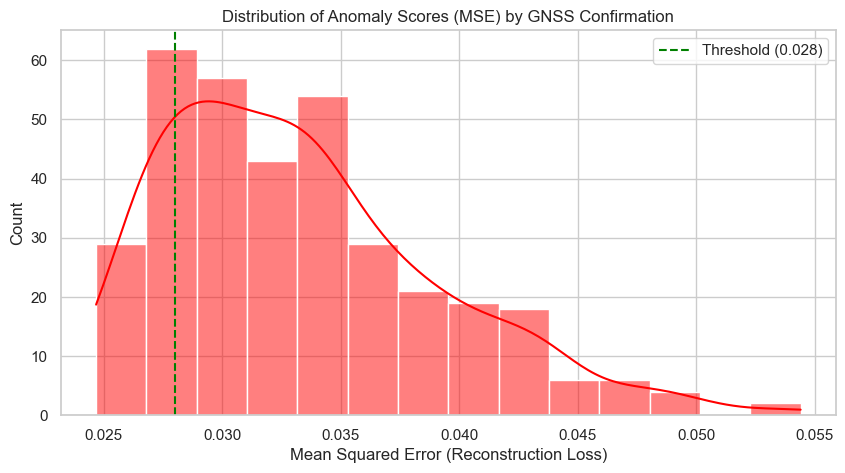

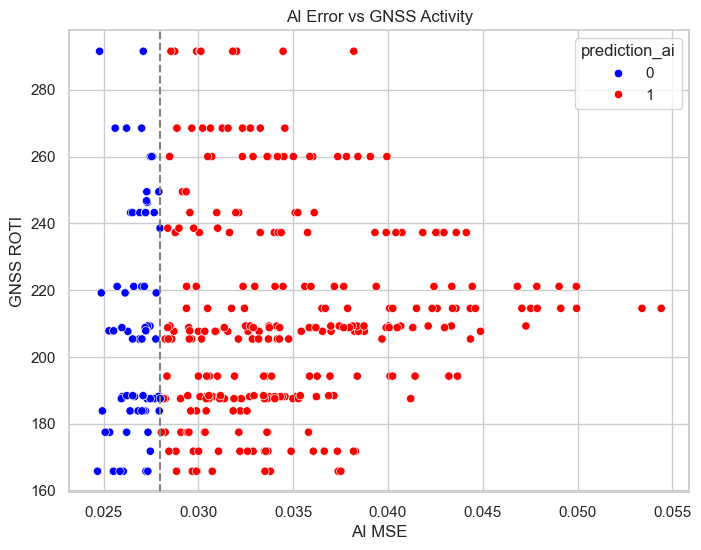

In [3]:
if os.path.exists(RESULTS_FILE):
    df_res = pd.read_csv(RESULTS_FILE)
    print(df_res.head())
    
    # MSE Distribution
    plt.figure(figsize=(10, 5))
    sns.histplot(data=df_res, x='mse', hue='ground_truth_gnss', kde=True, palette={0: 'blue', 1: 'red'})
    plt.title("Distribution of Anomaly Scores (MSE) by GNSS Confirmation")
    plt.xlabel("Mean Squared Error (Reconstruction Loss)")
    plt.axvline(x=0.028, color='green', linestyle='--', label='Threshold (0.028)')
    plt.legend()
    plt.show()
    
    # Scatter Plot
    plt.figure(figsize=(8, 6))
    sns.scatterplot(data=df_res, x='mse', y='gnss_max_roti', hue='prediction_ai', palette={0:'blue', 1:'red'})
    plt.title('AI Error vs GNSS Activity')
    plt.xlabel('AI MSE')
    plt.ylabel('GNSS ROTI')
    plt.axvline(x=0.028, color='gray', linestyle='--')
    plt.show()
else:
    print("Validation results not found. Run src/validate_pipeline.py first.")

## 3. Visual Samples
Comparing Clear vs Detected EPB images.

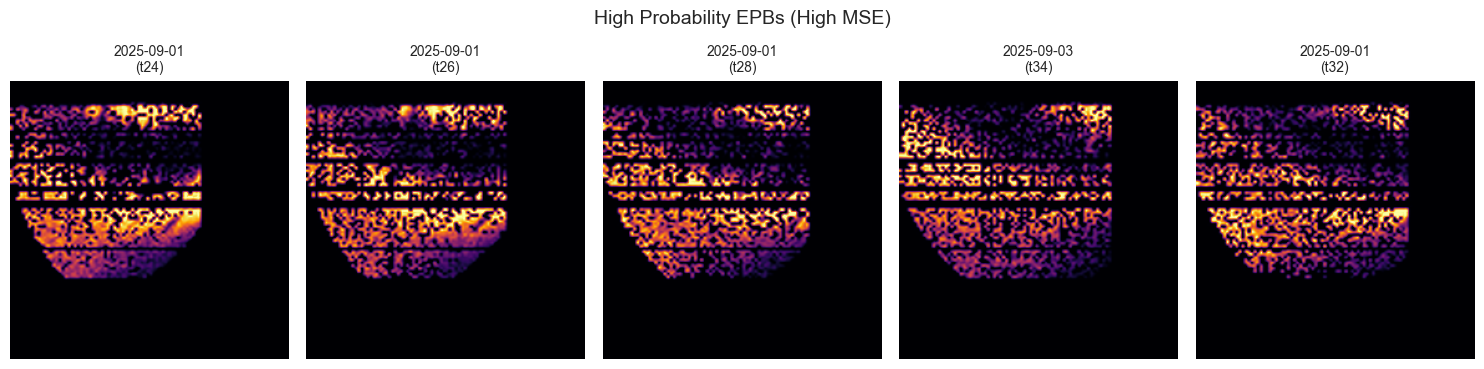

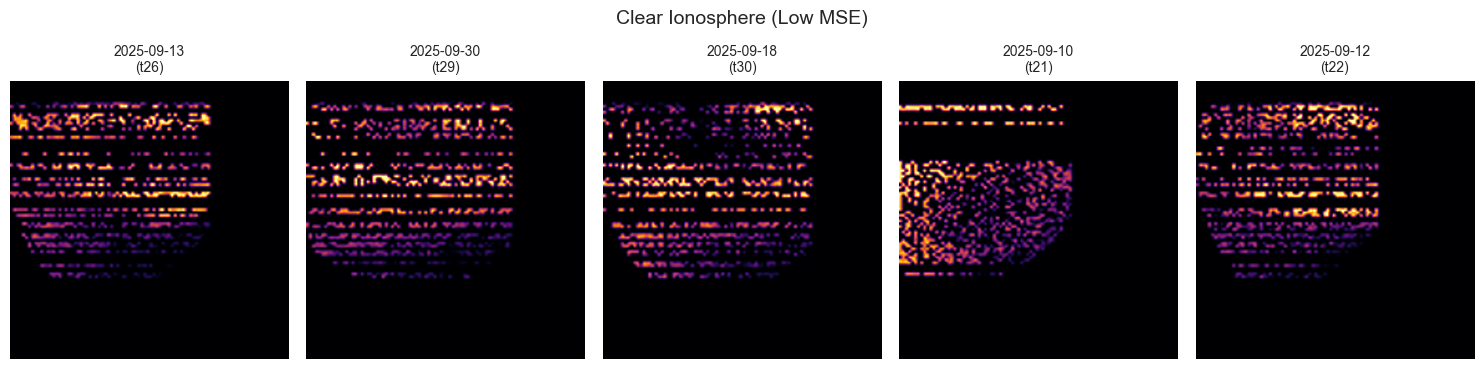

In [5]:
if os.path.exists(RESULTS_FILE):
    # Get top 5 highest MSE (Likely EPBs)
    top_epb = df_res.nlargest(5, 'mse')['filename'].values
    
    # Get top 5 lowest MSE (Likely Clear)
    top_clear = df_res.nsmallest(5, 'mse')['filename'].values
    
    def get_label(filename):
        # Filename: gold_l2_nmax_YYYY_DOY_..._tXX.png
        try:
            parts = filename.split('_')
            year = int(parts[3])
            doy = int(parts[4])
            t_val = parts[-1].replace('.png', '')
            
            date = pd.Timestamp(f"{year}-01-01") + pd.Timedelta(days=doy-1)
            date_str = date.strftime("%Y-%m-%d")
            return f"{date_str}\n({t_val})"
        except:
            return filename

    def show_images(filenames, title):
        plt.figure(figsize=(15, 4))
        for i, fname in enumerate(filenames):
            path = os.path.join(DATA_DIR, fname)
            if os.path.exists(path):
                img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
                plt.subplot(1, 5, i+1)
                plt.imshow(img, cmap='inferno')
                plt.title(get_label(fname), fontsize=10)
                plt.axis('off')
        plt.suptitle(title, fontsize=14)
        plt.tight_layout()
        plt.show()
        
    show_images(top_epb, "High Probability EPBs (High MSE)")
    show_images(top_clear, "Clear Ionosphere (Low MSE)")